# Evaluation of Text Separation Ability

This notebook evaluates how well the model can separate mixed embeddings after fine-tuning.

## Goal
Measure the rank of correct next token from text A when we feed `0.5 * emb(text_A) + 0.5 * emb(text_B)` into the model.

Lower rank = better separation ability.


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoConfig
from datasets import load_dataset
from model import DualStreamLLM
import numpy as np
from tqdm.auto import tqdm
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Device
device = torch.device('cuda:0')


In [2]:
## Configuration

# Evaluation parameters
NUM_SAMPLES = 500  # Number of text pairs to evaluate
MAX_LENGTH = 512   # Maximum sequence length
BATCH_SIZE = 8     # Batch size
SEED = 42          # Random seed

# Models to evaluate
CHECKPOINT_DIR = 'checkpoints'
RUNS_TO_EVALUATE = [
    'run_20251028_182407',  # mixup_alpha=0.4
    'run_20251030_145128',  # mixup_alpha=1.0
    'run_20251031_181041',  # mixup_alpha=0.65
]
CHECKPOINT_STEPS = [40000, 80000]

# Set seeds
torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"Configuration:")
print(f"  Device: {device}")
print(f"  Num samples: {NUM_SAMPLES}")
print(f"  Max length: {MAX_LENGTH}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Runs: {RUNS_TO_EVALUATE}")
print(f"  Checkpoint steps: {CHECKPOINT_STEPS}")


Configuration:
  Device: cuda:0
  Num samples: 500
  Max length: 512
  Batch size: 8
  Runs: ['run_20251028_182407', 'run_20251030_145128', 'run_20251031_181041']
  Checkpoint steps: [40000, 80000]


In [3]:
def compute_token_ranks_with_positions(logits, target_tokens, pad_token_id):
    """
    Compute the rank of target tokens in the predicted distribution.
    
    Returns:
        ranks_by_position: dict mapping position -> list of ranks at that position
        all_ranks: flat list of all ranks
        all_reciprocal_ranks: flat list of all reciprocal ranks
    """
    batch_size, seq_len, vocab_size = logits.shape
    
    ranks_by_position = defaultdict(list)
    all_ranks = []
    all_reciprocal_ranks = []
    
    for b in range(batch_size):
        for t in range(seq_len):
            target_token = target_tokens[b, t].item()
            
            # Skip padding tokens
            if target_token == pad_token_id or target_token == -100:
                continue
            
            # Get logits for this position
            position_logits = logits[b, t]  # [vocab_size]
            
            # Get score of target token
            target_score = position_logits[target_token].item()
            
            # Count how many tokens have higher score (rank = 1 means highest)
            rank = (position_logits > target_score).sum().item() + 1
            
            ranks_by_position[t].append(rank)
            all_ranks.append(rank)
            all_reciprocal_ranks.append(1.0 / rank)
    
    return ranks_by_position, all_ranks, all_reciprocal_ranks


In [4]:
def evaluate_model(model, tokenizer, dataset, num_samples, max_length, batch_size, device):
    """
    Evaluate a model's ability to separate mixed texts.
    
    Returns:
        metrics: dict with aggregate metrics
        ranks_by_position: dict mapping position -> list of ranks
    """
    model.eval()
    
    all_ranks = []
    all_reciprocal_ranks = []
    ranks_by_position = defaultdict(list)
    
    # Prepare data iterator
    data_iter = iter(dataset)
    num_batches = (num_samples + batch_size - 1) // batch_size
    
    with torch.no_grad():
        for _ in tqdm(range(num_batches), desc="Evaluating"):
            # Collect batch
            texts_A = []
            texts_B = []
            
            for _ in range(batch_size):
                try:
                    texts_A.append(next(data_iter)['text'])
                    texts_B.append(next(data_iter)['text'])
                except StopIteration:
                    break
            
            if len(texts_A) == 0:
                break
            
            # Tokenize
            encoded_A = tokenizer(
                texts_A,
                max_length=max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            encoded_B = tokenizer(
                texts_B,
                max_length=max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            input_ids_A = encoded_A['input_ids'].to(device)
            attention_mask_A = encoded_A['attention_mask'].to(device)
            input_ids_B = encoded_B['input_ids'].to(device)
            attention_mask_B = encoded_B['attention_mask'].to(device)
            
            # Create target: next token from text A
            next_tokens_A = input_ids_A[:, 1:].clone()
            
            # Pass mixed embeddings (50:50) through model
            lambdas = torch.full((input_ids_A.size(0),), 0.5, device=device)
            
            # Forward pass
            try:
                model_output = model(input_ids_A, attention_mask_A, input_ids_B, attention_mask_B, lambdas=lambdas)
            except Exception as e:
                print(f"Error during forward pass: {e}")
                continue
            
            # Handle tuple output (for 'separate' objective)
            logits = model_output[0] if isinstance(model_output, tuple) else model_output
            
            # Use logits[:, :-1, :] to align with next_tokens_A
            logits_shifted = logits[:, :-1, :].float()
            
            # Compute ranks with position tracking
            batch_ranks_by_pos, batch_ranks, batch_reciprocal_ranks = compute_token_ranks_with_positions(
                logits_shifted, 
                next_tokens_A, 
                tokenizer.pad_token_id
            )
            
            # Merge position-wise ranks
            for pos, ranks_list in batch_ranks_by_pos.items():
                ranks_by_position[pos].extend(ranks_list)
            
            all_ranks.extend(batch_ranks)
            all_reciprocal_ranks.extend(batch_reciprocal_ranks)
            
            # Stop if we've collected enough samples
            if len(all_ranks) >= num_samples * max_length:
                break
    
    # Compute aggregate metrics
    all_ranks = np.array(all_ranks)
    all_reciprocal_ranks = np.array(all_reciprocal_ranks)
    
    metrics = {
        'mean_rank': float(np.mean(all_ranks)),
        'median_rank': float(np.median(all_ranks)),
        'std_rank': float(np.std(all_ranks)),
        'mrr': float(np.mean(all_reciprocal_ranks)),
        'top1_acc': float(np.mean(all_ranks == 1)),
        'top5_acc': float(np.mean(all_ranks <= 5)),
        'top10_acc': float(np.mean(all_ranks <= 10)),
        'top50_acc': float(np.mean(all_ranks <= 50)),
        'num_samples': len(all_ranks)
    }
    
    return metrics, ranks_by_position


def evaluate_baseline_model(model, tokenizer, dataset, num_samples, max_length, batch_size, device):
    """
    Evaluate a baseline model (no mixup).
    
    Returns:
        metrics: dict with aggregate metrics
        ranks_by_position: dict mapping position -> list of ranks
    """
    model.eval()
    
    all_ranks = []
    all_reciprocal_ranks = []
    ranks_by_position = defaultdict(list)
    
    # Prepare data iterator
    data_iter = iter(dataset)
    num_batches = (num_samples + batch_size - 1) // batch_size
    
    with torch.no_grad():
        for _ in tqdm(range(num_batches), desc="Evaluating Baseline"):
            # Collect batch
            texts = []
            
            for _ in range(batch_size):
                try:
                    texts.append(next(data_iter)['text'])
                except StopIteration:
                    break
            
            if len(texts) == 0:
                break
            
            # Tokenize
            encoded = tokenizer(
                texts,
                max_length=max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            input_ids = encoded['input_ids'].to(device)
            attention_mask = encoded['attention_mask'].to(device)
            
            # Create target: next token
            next_tokens = input_ids[:, 1:].clone()
            
            # Forward pass (no mixup)
            try:
                # The model expects two inputs, but for baseline we provide the same one twice
                # with lambda=0 to effectively use only the first input.
                model_output = model(input_ids, attention_mask, input_ids, attention_mask, lambdas=torch.zeros(input_ids.size(0), device=device))
            except Exception as e:
                print(f"Error during forward pass: {e}")
                continue
            
            # Handle tuple output (for 'separate' objective)
            logits = model_output[0] if isinstance(model_output, tuple) else model_output
            
            # Use logits[:, :-1, :] to align with next_tokens
            logits_shifted = logits[:, :-1, :].float()
            
            # Compute ranks
            batch_ranks_by_pos, batch_ranks, batch_reciprocal_ranks = compute_token_ranks_with_positions(
                logits_shifted, 
                next_tokens, 
                tokenizer.pad_token_id
            )
            
            # Merge position-wise ranks
            for pos, ranks_list in batch_ranks_by_pos.items():
                ranks_by_position[pos].extend(ranks_list)
            
            all_ranks.extend(batch_ranks)
            all_reciprocal_ranks.extend(batch_reciprocal_ranks)
            
            # Stop if we've collected enough samples
            if len(all_ranks) >= num_samples * max_length:
                break
    
    # Compute aggregate metrics
    all_ranks = np.array(all_ranks)
    all_reciprocal_ranks = np.array(all_reciprocal_ranks)
    
    metrics = {
        'mean_rank': float(np.mean(all_ranks)),
        'median_rank': float(np.median(all_ranks)),
        'std_rank': float(np.std(all_ranks)),
        'mrr': float(np.mean(all_reciprocal_ranks)),
        'top1_acc': float(np.mean(all_ranks == 1)),
        'top5_acc': float(np.mean(all_ranks <= 5)),
        'top10_acc': float(np.mean(all_ranks <= 10)),
        'top50_acc': float(np.mean(all_ranks <= 50)),
        'num_samples': len(all_ranks)
    }
    
    return metrics, ranks_by_position


In [5]:
def load_model_from_checkpoint(checkpoint_path, config, device):
    """Load a DualStreamLLM model from checkpoint."""
    
    # Get vocab_size and hidden_dim from the base model config
    base_model_config = AutoConfig.from_pretrained(config['model_name'])
    vocab_size = base_model_config.vocab_size
    hidden_dim = base_model_config.hidden_size
    
    model = DualStreamLLM(
        model_name=config['model_name'],
        vocab_size=vocab_size,
        hidden_dim=hidden_dim,
        freeze_backbone=True,  # Assuming we always evaluate with frozen backbone
        embedding_init_strategy=config.get('embedding_init_strategy', 'copy'),
        unembedding_init_strategy=config.get('unembedding_init_strategy', 'copy'),
        embedding_init_noise_std=config.get('embedding_init_noise_std', 0.01),
        objective=config.get('objective', 'mixup'), # Default to mixup if not specified
        shared_embeddings=config.get('shared_embeddings', False)
    )
    
    checkpoint = torch.load(checkpoint_path, map_location='cpu')
    
    # Handle potential DataParallel wrapper
    state_dict = checkpoint['model_state_dict']
    if list(state_dict.keys())[0].startswith('module.'):
        state_dict = {k[7:]: v for k, v in state_dict.items()}
        
    model.load_state_dict(state_dict)
    
    model = model.to(device)
    model.eval()
    
    return model


In [6]:
def plot_ranks_by_position(ranks_by_position, title, figsize=(12, 6)):
    """
    Plot average rank vs token position.
    
    Args:
        ranks_by_position: dict mapping position -> list of ranks
        title: plot title
    """
    positions = sorted(ranks_by_position.keys())
    mean_ranks = [np.mean(ranks_by_position[pos]) for pos in positions]
    
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(positions, mean_ranks, linewidth=2, marker='o', markersize=3, alpha=0.7)
    ax.set_xlabel('Token Position in Sequence', fontsize=12)
    ax.set_ylabel('Average Rank', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add horizontal line for reference
    overall_mean = np.mean(mean_ranks)
    ax.axhline(y=overall_mean, color='r', linestyle='--', alpha=0.5, 
               label=f'Overall Mean: {overall_mean:.1f}')
    ax.legend()
    
    plt.tight_layout()
    return fig


In [7]:
def print_metrics(metrics, model_name):
    """Print evaluation metrics in a nice format."""
    print(f"\n{'='*70}")
    print(f"Results for: {model_name}")
    print(f"{'='*70}")
    print(f"  Mean Rank:        {metrics['mean_rank']:.2f}")
    print(f"  Median Rank:      {metrics['median_rank']:.2f}")
    print(f"  Std Rank:         {metrics['std_rank']:.2f}")
    print(f"  MRR:              {metrics['mrr']:.4f}")
    print(f"  Top-1 Accuracy:   {metrics['top1_acc']*100:.2f}%")
    print(f"  Top-5 Accuracy:   {metrics['top5_acc']*100:.2f}%")
    print(f"  Top-10 Accuracy:  {metrics['top10_acc']*100:.2f}%")
    print(f"  Top-50 Accuracy:  {metrics['top50_acc']*100:.2f}%")
    print(f"  Num samples:      {metrics['num_samples']}")
    print(f"{'='*70}\n")


## Load Tokenizer and Dataset


In [8]:
# Load tokenizer
model_name = 'HuggingFaceTB/SmolLM2-135M'
tokenizer = AutoTokenizer.from_pretrained(model_name)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"Loaded tokenizer: {model_name}")
print(f"  Vocab size: {tokenizer.vocab_size}")
print(f"  Pad token: {tokenizer.pad_token}")

# Load dataset
print("\nLoading dataset...")
dataset = load_dataset('roneneldan/TinyStories', split='train', streaming=True, trust_remote_code=True)
dataset = dataset.shuffle(seed=SEED, buffer_size=10000)
print("Dataset loaded and shuffled!")


Loaded tokenizer: HuggingFaceTB/SmolLM2-135M
  Vocab size: 49152
  Pad token: <|endoftext|>

Loading dataset...
Dataset loaded and shuffled!


## 1. Evaluate Baseline Model (Fine-tuned on TinyStories, No Mixup)

We run this once and save the results for comparison. The baseline is a model fine-tuned on TinyStories with a standard language modeling objective, evaluated on single, unmixed texts.


--- Loading New Baseline Model ---
Run: run_20251027_235405, Step: 80000

--- Evaluating New Baseline Model (No Mixup) ---


Evaluating Baseline:   0%|          | 0/63 [00:00<?, ?it/s]


Results for: BASELINE (run_20251027_235405)
  Mean Rank:        12.39
  Median Rank:      1.00
  Std Rank:         175.25
  MRR:              0.6778
  Top-1 Accuracy:   55.72%
  Top-5 Accuracy:   83.05%
  Top-10 Accuracy:  89.53%
  Top-50 Accuracy:  96.99%
  Num samples:      116118



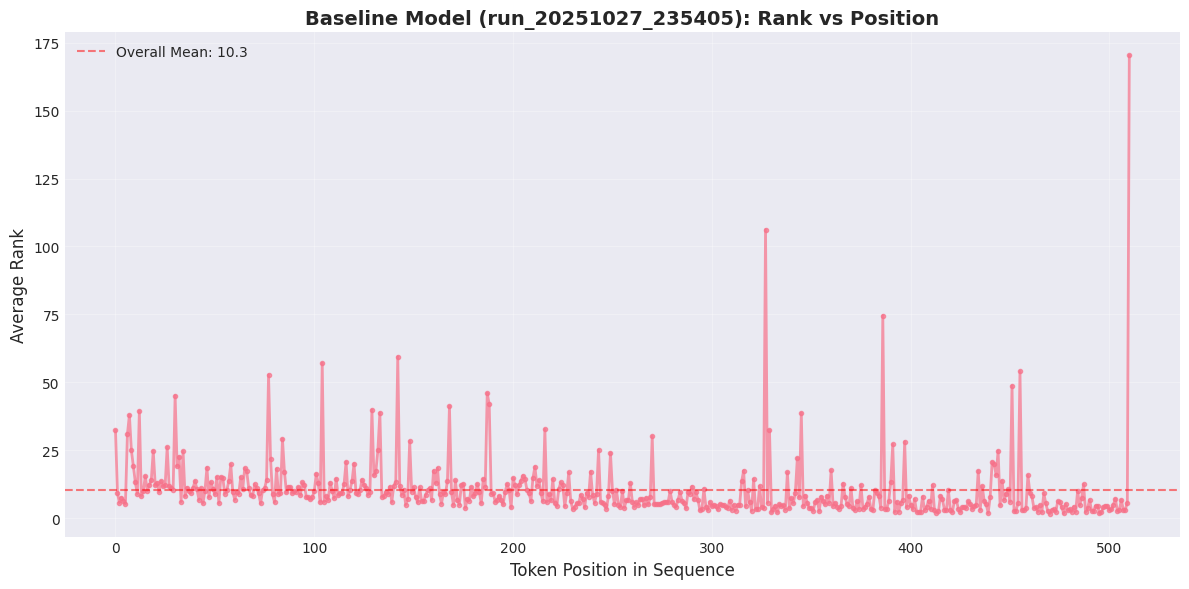


✅ Baseline model evaluation complete!


In [9]:
# --- CONFIGURATION FOR THE NEW BASELINE ---
BASELINE_RUN_NAME = 'run_20251027_235405' # The run trained WITHOUT mixup
BASELINE_CHECKPOINT_STEP = 80000
# ---

# Construct paths
baseline_run_dir = os.path.join(CHECKPOINT_DIR, BASELINE_RUN_NAME)
baseline_config_path = os.path.join(baseline_run_dir, 'training_config.json')
baseline_checkpoint_path = os.path.join(baseline_run_dir, f'checkpoint-{BASELINE_CHECKPOINT_STEP}', 'model.pt')

print("--- Loading New Baseline Model ---")
print(f"Run: {BASELINE_RUN_NAME}, Step: {BASELINE_CHECKPOINT_STEP}")

# Load config
with open(baseline_config_path, 'r') as f:
    baseline_config = json.load(f)

# Load model
baseline_model = load_model_from_checkpoint(baseline_checkpoint_path, baseline_config, device)

print("\n--- Evaluating New Baseline Model (No Mixup) ---")
# Reset dataset for fresh evaluation
dataset_base = dataset.shuffle(seed=SEED, buffer_size=10000)
base_metrics, base_ranks_by_pos = evaluate_baseline_model(
    baseline_model, 
    tokenizer, 
    dataset_base, 
    NUM_SAMPLES, 
    MAX_LENGTH, 
    BATCH_SIZE, 
    device
)

# Print results
print_metrics(base_metrics, f"BASELINE ({BASELINE_RUN_NAME})")

# Plot
fig = plot_ranks_by_position(base_ranks_by_pos, f"Baseline Model ({BASELINE_RUN_NAME}): Rank vs Position")
plt.show()

# Clean up
del baseline_model
torch.cuda.empty_cache()

print("\n✅ Baseline model evaluation complete!")


## 2. Evaluate Fine-Tuned Models

Now we evaluate each fine-tuned model and compare with baseline.


In [10]:
# Storage for all results
all_results = {
    'base': {
        'metrics': base_metrics,
        'ranks_by_pos': base_ranks_by_pos,
        'label': f'Baseline ({BASELINE_RUN_NAME})'
    }
}

print("All results will be stored in 'all_results' dict for final comparison.")


All results will be stored in 'all_results' dict for final comparison.


### 2.1. run_20251028_182407 (mixup_alpha=0.4)



Evaluating: run_20251028_182407
mixup_alpha: 0.4


--- Checkpoint: step 40000 ---


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]


Results for: run_20251028_182407 (α=0.4, step 40000)
  Mean Rank:        69.65
  Median Rank:      4.00
  Std Rank:         404.91
  MRR:              0.4043
  Top-1 Accuracy:   27.80%
  Top-5 Accuracy:   54.93%
  Top-10 Accuracy:  65.66%
  Top-50 Accuracy:  84.19%
  Num samples:      116046

  Improvement vs Base:
    Mean Rank: -57.26 (negative = worse, positive = better)
    MRR: -0.2735 (negative = worse, positive = better)



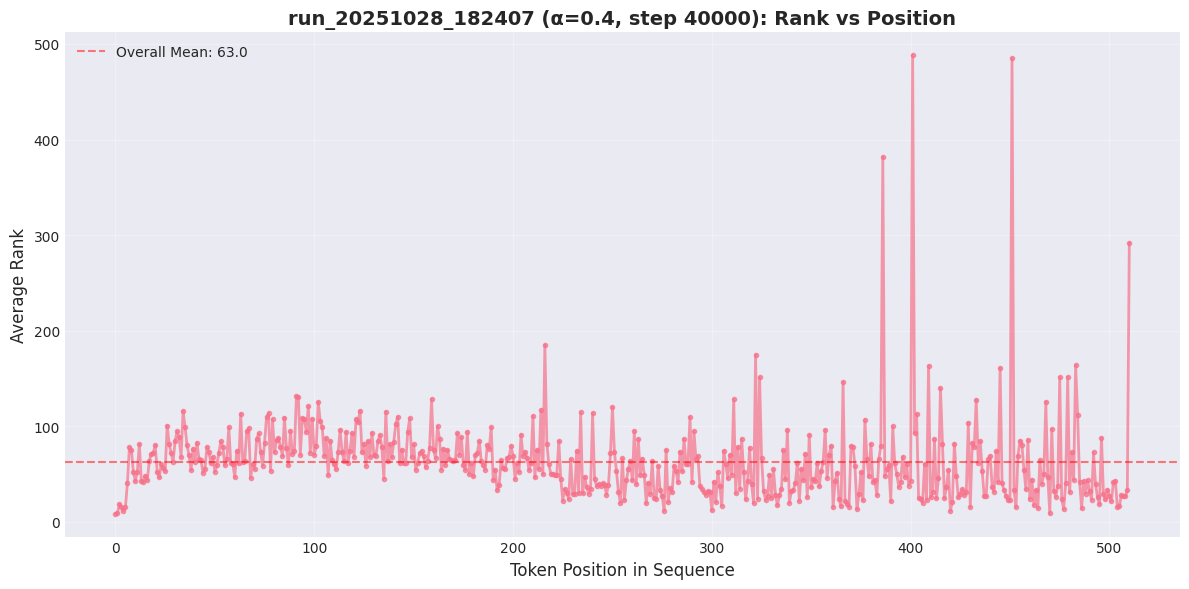


--- Checkpoint: step 80000 ---


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]


Results for: run_20251028_182407 (α=0.4, step 80000)
  Mean Rank:        68.01
  Median Rank:      4.00
  Std Rank:         392.15
  MRR:              0.4072
  Top-1 Accuracy:   28.05%
  Top-5 Accuracy:   55.31%
  Top-10 Accuracy:  65.93%
  Top-50 Accuracy:  84.46%
  Num samples:      116046

  Improvement vs Base:
    Mean Rank: -55.62 (negative = worse, positive = better)
    MRR: -0.2706 (negative = worse, positive = better)



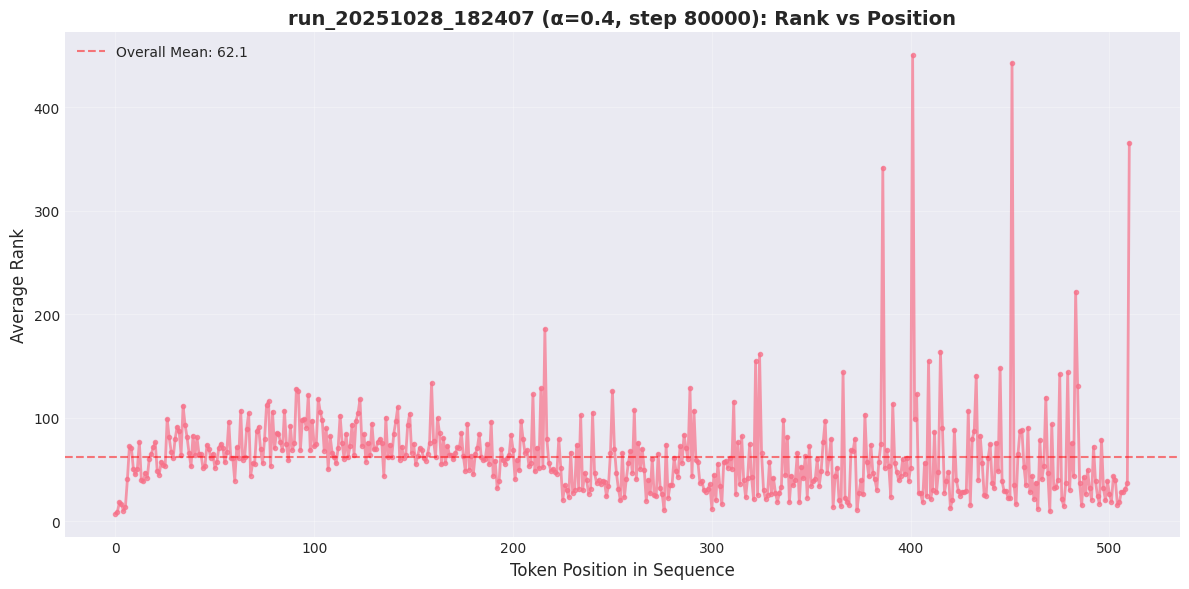


✅ run_20251028_182407 evaluation complete!


In [11]:
run_name = 'run_20251028_182407'
run_dir = os.path.join(CHECKPOINT_DIR, run_name)

# Load config
config_path = os.path.join(run_dir, 'training_config.json')
with open(config_path, 'r') as f:
    config = json.load(f)

print(f"\n{'='*70}")
print(f"Evaluating: {run_name}")
print(f"mixup_alpha: {config.get('mixup_alpha', 'N/A')}")
print(f"{'='*70}\n")

# Evaluate each checkpoint
for step in CHECKPOINT_STEPS:
    checkpoint_path = os.path.join(run_dir, f'checkpoint-{step}', 'model.pt')
    
    if not os.path.exists(checkpoint_path):
        print(f"⚠️  Checkpoint not found: {checkpoint_path}")
        continue
    
    print(f"\n--- Checkpoint: step {step} ---")
    
    # Load model
    model = load_model_from_checkpoint(checkpoint_path, config, device)
    
    # Evaluate
    dataset_eval = dataset.shuffle(seed=SEED, buffer_size=10000)
    metrics, ranks_by_pos = evaluate_model(
        model, 
        tokenizer, 
        dataset_eval, 
        NUM_SAMPLES, 
        MAX_LENGTH, 
        BATCH_SIZE, 
        device
    )
    
    # Store results
    key = f"{run_name}_step{step}"
    label = f"{run_name} (α={config['mixup_alpha']}, step {step})"
    all_results[key] = {
        'metrics': metrics,
        'ranks_by_pos': ranks_by_pos,
        'label': label,
        'run_name': run_name,
        'step': step,
        'mixup_alpha': config['mixup_alpha']
    }
    
    # Print metrics
    print_metrics(metrics, label)
    
    # Compare with base
    improvement = base_metrics['mean_rank'] - metrics['mean_rank']
    mrr_improvement = metrics['mrr'] - base_metrics['mrr']
    print(f"  Improvement vs Base:")
    print(f"    Mean Rank: {improvement:+.2f} (negative = worse, positive = better)")
    print(f"    MRR: {mrr_improvement:+.4f} (negative = worse, positive = better)\n")
    
    # Plot
    fig = plot_ranks_by_position(ranks_by_pos, f"{label}: Rank vs Position")
    plt.show()
    
    # Clean up
    del model
    torch.cuda.empty_cache()

print(f"\n✅ {run_name} evaluation complete!")


### 2.2. run_20251030_145128 (mixup_alpha=1.0)



Evaluating: run_20251030_145128
mixup_alpha: 1.0


--- Checkpoint: step 40000 ---


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]


Results for: run_20251030_145128 (α=1.0, step 40000)
  Mean Rank:        56.30
  Median Rank:      4.00
  Std Rank:         358.43
  MRR:              0.4253
  Top-1 Accuracy:   29.42%
  Top-5 Accuracy:   57.73%
  Top-10 Accuracy:  68.37%
  Top-50 Accuracy:  86.29%
  Num samples:      116046

  Improvement vs Base:
    Mean Rank: -43.91 (negative = worse, positive = better)
    MRR: -0.2524 (negative = worse, positive = better)



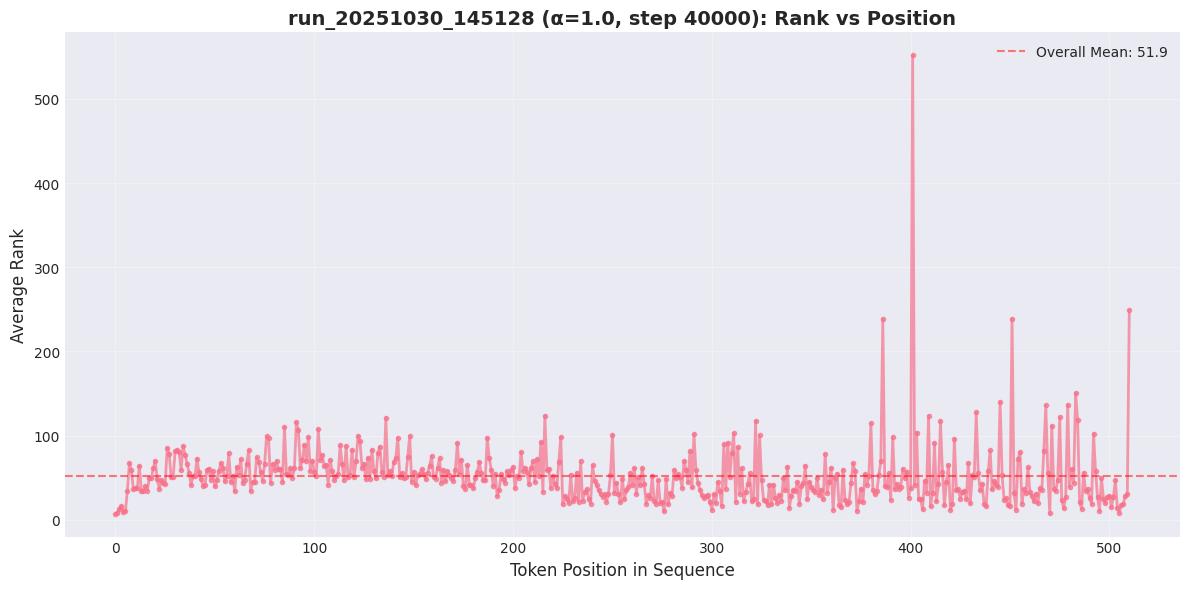


--- Checkpoint: step 80000 ---


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]


Results for: run_20251030_145128 (α=1.0, step 80000)
  Mean Rank:        56.11
  Median Rank:      4.00
  Std Rank:         354.91
  MRR:              0.4266
  Top-1 Accuracy:   29.59%
  Top-5 Accuracy:   57.92%
  Top-10 Accuracy:  68.41%
  Top-50 Accuracy:  86.31%
  Num samples:      116046

  Improvement vs Base:
    Mean Rank: -43.72 (negative = worse, positive = better)
    MRR: -0.2512 (negative = worse, positive = better)



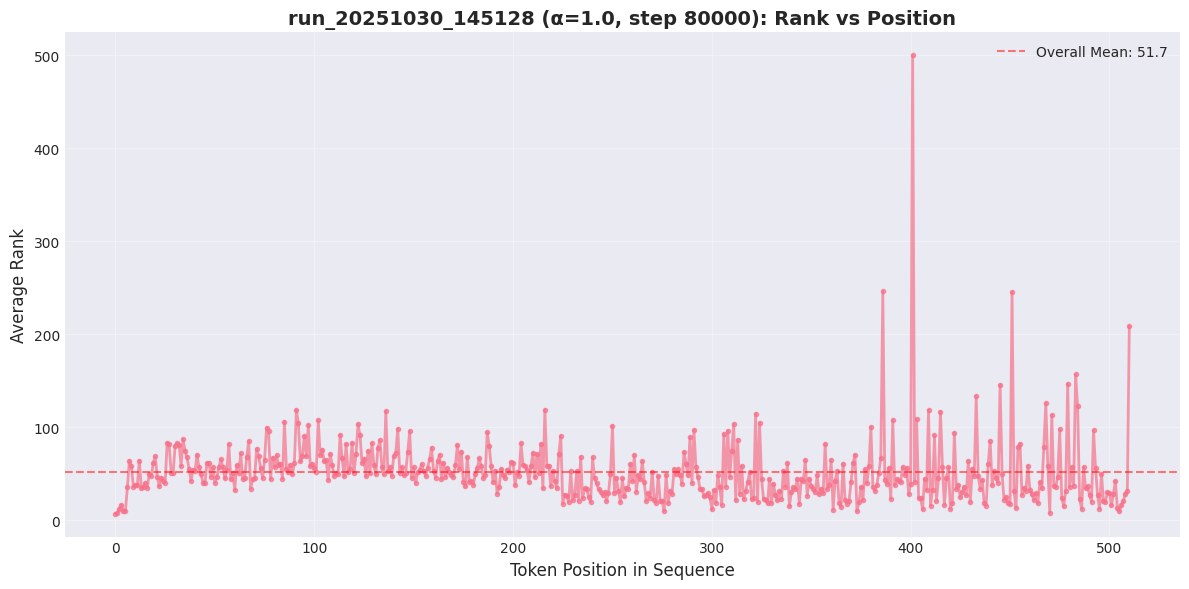


✅ run_20251030_145128 evaluation complete!


In [12]:
run_name = 'run_20251030_145128'
run_dir = os.path.join(CHECKPOINT_DIR, run_name)

# Load config
config_path = os.path.join(run_dir, 'training_config.json')
with open(config_path, 'r') as f:
    config = json.load(f)

print(f"\n{'='*70}")
print(f"Evaluating: {run_name}")
print(f"mixup_alpha: {config.get('mixup_alpha', 'N/A')}")
print(f"{'='*70}\n")

# Evaluate each checkpoint
for step in CHECKPOINT_STEPS:
    checkpoint_path = os.path.join(run_dir, f'checkpoint-{step}', 'model.pt')
    
    if not os.path.exists(checkpoint_path):
        print(f"⚠️  Checkpoint not found: {checkpoint_path}")
        continue
    
    print(f"\n--- Checkpoint: step {step} ---")
    
    # Load model
    model = load_model_from_checkpoint(checkpoint_path, config, device)
    
    # Evaluate
    dataset_eval = dataset.shuffle(seed=SEED, buffer_size=10000)
    metrics, ranks_by_pos = evaluate_model(
        model, 
        tokenizer, 
        dataset_eval, 
        NUM_SAMPLES, 
        MAX_LENGTH, 
        BATCH_SIZE, 
        device
    )
    
    # Store results
    key = f"{run_name}_step{step}"
    label = f"{run_name} (α={config['mixup_alpha']}, step {step})"
    all_results[key] = {
        'metrics': metrics,
        'ranks_by_pos': ranks_by_pos,
        'label': label,
        'run_name': run_name,
        'step': step,
        'mixup_alpha': config['mixup_alpha']
    }
    
    # Print metrics
    print_metrics(metrics, label)
    
    # Compare with base
    improvement = base_metrics['mean_rank'] - metrics['mean_rank']
    mrr_improvement = metrics['mrr'] - base_metrics['mrr']
    print(f"  Improvement vs Base:")
    print(f"    Mean Rank: {improvement:+.2f} (negative = worse, positive = better)")
    print(f"    MRR: {mrr_improvement:+.4f} (negative = worse, positive = better)\n")
    
    # Plot
    fig = plot_ranks_by_position(ranks_by_pos, f"{label}: Rank vs Position")
    plt.show()
    
    # Clean up
    del model
    torch.cuda.empty_cache()

print(f"\n✅ {run_name} evaluation complete!")


### 2.3. run_20251031_181041 (mixup_alpha=0.65)



Evaluating: run_20251031_181041
mixup_alpha: 0.65


--- Checkpoint: step 40000 ---


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]


Results for: run_20251031_181041 (α=0.65, step 40000)
  Mean Rank:        62.53
  Median Rank:      4.00
  Std Rank:         394.45
  MRR:              0.4164
  Top-1 Accuracy:   28.79%
  Top-5 Accuracy:   56.60%
  Top-10 Accuracy:  67.23%
  Top-50 Accuracy:  85.40%
  Num samples:      116046

  Improvement vs Base:
    Mean Rank: -50.14
    MRR: -0.2614



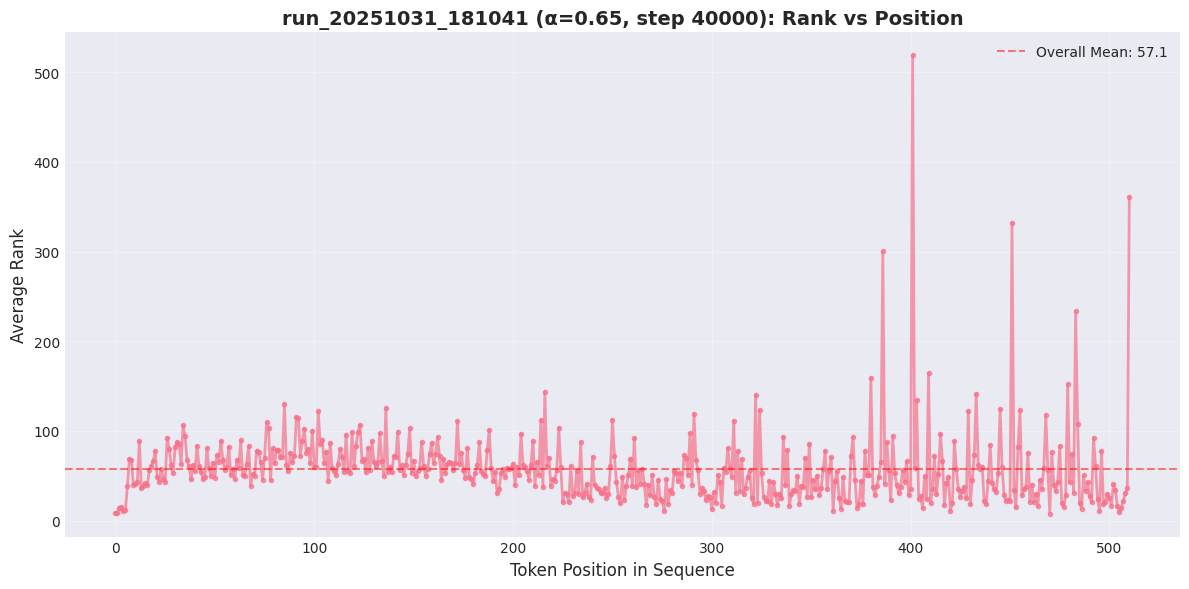


--- Checkpoint: step 80000 ---


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]


Results for: run_20251031_181041 (α=0.65, step 80000)
  Mean Rank:        61.24
  Median Rank:      4.00
  Std Rank:         375.85
  MRR:              0.4185
  Top-1 Accuracy:   28.92%
  Top-5 Accuracy:   56.90%
  Top-10 Accuracy:  67.53%
  Top-50 Accuracy:  85.62%
  Num samples:      116046

  Improvement vs Base:
    Mean Rank: -48.85
    MRR: -0.2593



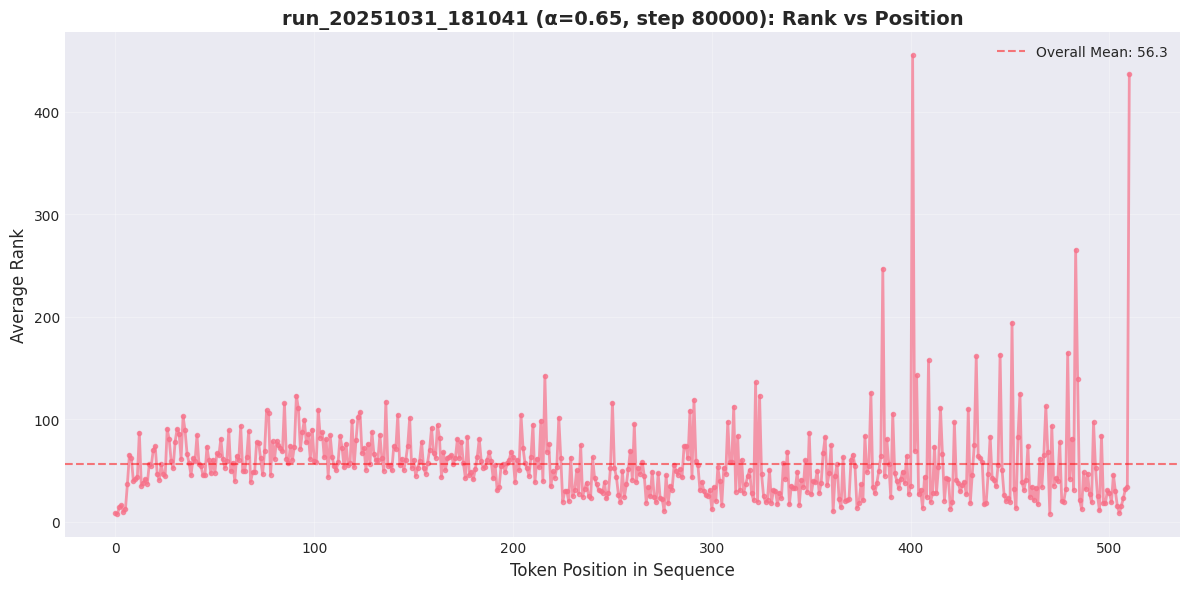


✅ run_20251031_181041 evaluation complete!


In [13]:
run_name = 'run_20251031_181041'
run_dir = os.path.join(CHECKPOINT_DIR, run_name)

config_path = os.path.join(run_dir, 'training_config.json')
with open(config_path, 'r') as f:
    config = json.load(f)

print(f"\n{'='*70}")
print(f"Evaluating: {run_name}")
print(f"mixup_alpha: {config.get('mixup_alpha', 'N/A')}")
print(f"{'='*70}\n")

for step in CHECKPOINT_STEPS:
    checkpoint_path = os.path.join(run_dir, f'checkpoint-{step}', 'model.pt')
    
    if not os.path.exists(checkpoint_path):
        print(f"⚠️  Checkpoint not found: {checkpoint_path}")
        continue
    
    print(f"\n--- Checkpoint: step {step} ---")
    
    model = load_model_from_checkpoint(checkpoint_path, config, device)
    
    dataset_eval = dataset.shuffle(seed=SEED, buffer_size=10000)
    metrics, ranks_by_pos = evaluate_model(
        model, tokenizer, dataset_eval, NUM_SAMPLES, MAX_LENGTH, BATCH_SIZE, device
    )
    
    key = f"{run_name}_step{step}"
    label = f"{run_name} (α={config['mixup_alpha']}, step {step})"
    all_results[key] = {
        'metrics': metrics,
        'ranks_by_pos': ranks_by_pos,
        'label': label,
        'run_name': run_name,
        'step': step,
        'mixup_alpha': config['mixup_alpha']
    }
    
    print_metrics(metrics, label)
    
    improvement = base_metrics['mean_rank'] - metrics['mean_rank']
    mrr_improvement = metrics['mrr'] - base_metrics['mrr']
    print(f"  Improvement vs Base:")
    print(f"    Mean Rank: {improvement:+.2f}")
    print(f"    MRR: {mrr_improvement:+.4f}\n")
    
    fig = plot_ranks_by_position(ranks_by_pos, f"{label}: Rank vs Position")
    plt.show()
    
    del model
    torch.cuda.empty_cache()

print(f"\n✅ {run_name} evaluation complete!")


## 3. Final Comparison: All Models Together

Now let's plot all models on the same graph to compare them visually.


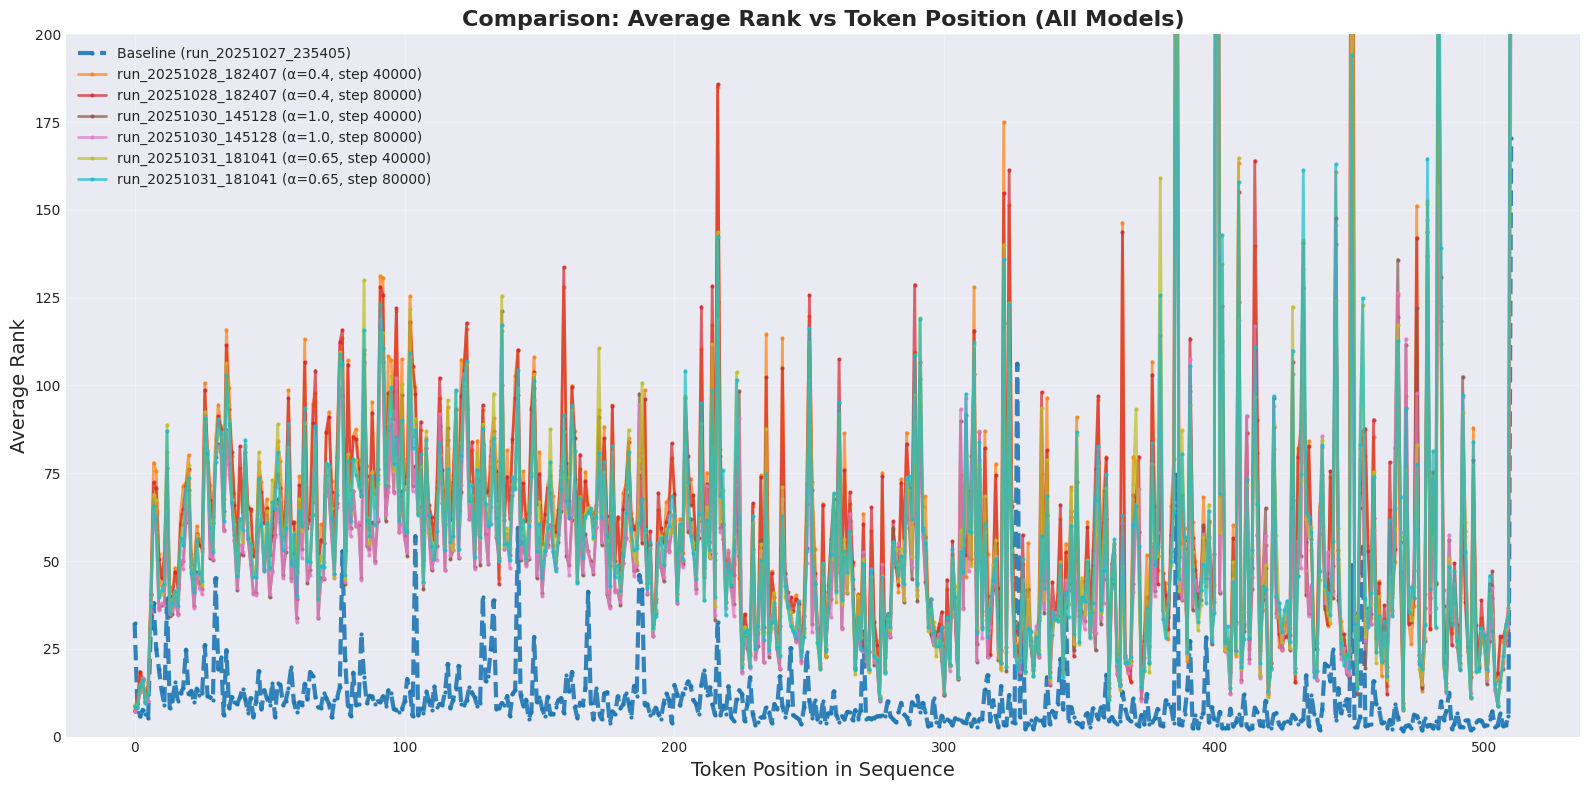


✅ Comparison plot complete!


In [17]:
# Plot all models together
fig, ax = plt.subplots(figsize=(16, 8))

colors = plt.cm.tab10(np.linspace(0, 1, len(all_results)))

for idx, (key, result) in enumerate(all_results.items()):
    ranks_by_pos = result['ranks_by_pos']
    label = result['label']
    
    positions = sorted(ranks_by_pos.keys())
    mean_ranks = [np.mean(ranks_by_pos[pos]) for pos in positions]
    
    linestyle = '--' if key == 'base' else '-'
    linewidth = 3 if key == 'base' else 2
    alpha = 0.9 if key == 'base' else 0.7
    
    ax.plot(positions, mean_ranks, linewidth=linewidth, linestyle=linestyle, 
            marker='o', markersize=2, alpha=alpha, label=label, color=colors[idx])

ax.set_xlabel('Token Position in Sequence', fontsize=14)
ax.set_ylabel('Average Rank', fontsize=14)
ax.set_title('Comparison: Average Rank vs Token Position (All Models)', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 200)
ax.legend(loc='best', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

print("\n✅ Comparison plot complete!")


## Summary Table


In [15]:
# Create summary table
import pandas as pd

summary_data = []
for key, result in all_results.items():
    metrics = result['metrics']
    row = {
        'Model': result['label'],
        'Mean Rank': f"{metrics['mean_rank']:.2f}",
        'Median Rank': f"{metrics['median_rank']:.2f}",
        'MRR': f"{metrics['mrr']:.4f}",
        'Top-1%': f"{metrics['top1_acc']*100:.2f}",
        'Top-5%': f"{metrics['top5_acc']*100:.2f}",
        'Top-10%': f"{metrics['top10_acc']*100:.2f}",
    }
    
    # Add improvement columns (skip for base)
    if key != 'base':
        improvement = base_metrics['mean_rank'] - metrics['mean_rank']
        mrr_improvement = metrics['mrr'] - base_metrics['mrr']
        row['ΔRank vs Base'] = f"{improvement:+.2f}"
        row['ΔMRR vs Base'] = f"{mrr_improvement:+.4f}"
    else:
        row['ΔRank vs Base'] = '-'
        row['ΔMRR vs Base'] = '-'
    
    summary_data.append(row)

df_summary = pd.DataFrame(summary_data)
print("\n" + "="*100)
print("FINAL SUMMARY TABLE")
print("="*100)
print(df_summary.to_string(index=False))
print("="*100)

# Display as HTML in notebook
from IPython.display import display
display(df_summary)



FINAL SUMMARY TABLE
                                   Model Mean Rank Median Rank    MRR Top-1% Top-5% Top-10% ΔRank vs Base ΔMRR vs Base
          Baseline (run_20251027_235405)     12.39        1.00 0.6778  55.72  83.05   89.53             -            -
 run_20251028_182407 (α=0.4, step 40000)     69.65        4.00 0.4043  27.80  54.93   65.66        -57.26      -0.2735
 run_20251028_182407 (α=0.4, step 80000)     68.01        4.00 0.4072  28.05  55.31   65.93        -55.62      -0.2706
 run_20251030_145128 (α=1.0, step 40000)     56.30        4.00 0.4253  29.42  57.73   68.37        -43.91      -0.2524
 run_20251030_145128 (α=1.0, step 80000)     56.11        4.00 0.4266  29.59  57.92   68.41        -43.72      -0.2512
run_20251031_181041 (α=0.65, step 40000)     62.53        4.00 0.4164  28.79  56.60   67.23        -50.14      -0.2614
run_20251031_181041 (α=0.65, step 80000)     61.24        4.00 0.4185  28.92  56.90   67.53        -48.85      -0.2593


,Model,Mean Rank,Median Rank,MRR,Top-1%,Top-5%,Top-10%,ΔRank vs Base,ΔMRR vs Base
0,Baseline (run_20251027_235405),12.39,1.00,0.6778,55.72,83.05,89.53,-,-
1,"run_20251028_182407 (α=0.4, step 40000)",69.65,4.00,0.4043,27.80,54.93,65.66,-57.26,-0.2735
2,"run_20251028_182407 (α=0.4, step 80000)",68.01,4.00,0.4072,28.05,55.31,65.93,-55.62,-0.2706
3,"run_20251030_145128 (α=1.0, step 40000)",56.30,4.00,0.4253,29.42,57.73,68.37,-43.91,-0.2524
4,"run_20251030_145128 (α=1.0, step 80000)",56.11,4.00,0.4266,29.59,57.92,68.41,-43.72,-0.2512
5,"run_20251031_181041 (α=0.65, step 40000)",62.53,4.00,0.4164,28.79,56.60,67.23,-50.14,-0.2614
6,"run_20251031_181041 (α=0.65, step 80000)",61.24,4.00,0.4185,28.92,56.90,67.53,-48.85,-0.2593


## Save Results to JSON


In [16]:
# Save results to JSON
output_file = 'separation_evaluation_results.json'

# Prepare data for JSON (convert ranks_by_pos to serializable format)
json_results = {}
for key, result in all_results.items():
    json_results[key] = {
        'label': result['label'],
        'metrics': result['metrics'],
        # Save only aggregated position stats, not full lists (too large)
        'mean_rank_by_position': {
            str(pos): float(np.mean(ranks)) 
            for pos, ranks in result['ranks_by_pos'].items()
        }
    }
    
    # Add metadata for fine-tuned models
    if key != 'base':
        json_results[key]['run_name'] = result['run_name']
        json_results[key]['step'] = result['step']
        json_results[key]['mixup_alpha'] = result['mixup_alpha']

# Save
with open(output_file, 'w') as f:
    json.dump(json_results, f, indent=2)

print(f"\n✅ Results saved to: {output_file}")
print(f"   File size: {os.path.getsize(output_file) / 1024:.2f} KB")



✅ Results saved to: separation_evaluation_results.json
   File size: 112.52 KB
